# 08 · Short records, how the model decides, and where it's wrong

Three questions about the model from notebook 07 (shrunk history + "who they beat"):
1. **Short records.** Many fighters have fewer than 5 UFC fights. How much worse are those predictions, and do age, size, reach and style carry more weight then?
2. **How does it decide?** Which features drive the predictions, overall and for a single fight?
3. **Where is it wrong?** Which kinds of fights does it miss, and what do the biggest upsets have in common?

In [1]:
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

from ufc import form as F, modeling as M
from ufc.features import MIN_FEATURES, HIST_FEATURES
from ufc.viz import use_style, SERIES, INK_2, NEUTRAL, GRID, METHOD_COLORS
from sklearn.metrics import log_loss, accuracy_score
from sklearn.inspection import permutation_importance
use_style()

K_SHRINK, K_METHOD = 5, 6                 # chosen on 2021-23 validation in notebook 07
t, ff = M.load_model_table(shrink_k=K_SHRINK)
train, test = t[t.date < M.SPLIT], t[t.date >= M.SPLIT].reset_index(drop=True)

BASE = M.diffs(MIN_FEATURES + HIST_FEATURES) + M.FLAGS + ["red_corner"]
FINAL_COLS = BASE + M.diffs(F.OPP_FEATURES)                     # the validation-chosen model
ALL_COLS = BASE + M.diffs(F.FORM_FEATURES + F.OPP_FEATURES + F.SOS_FEATURES + F.COMMON_FEATURES + F.STYLE_FEATURES + ["elo_pre"])
PHYS_COLS = M.diffs(["age_at_fight", "height", "reach", "reach_height", "southpaw"]) + M.FLAGS + ["red_corner"]

final = M.fit(M.logistic(), train, FINAL_COLS)
test["p_red"] = M.predict(final, test, FINAL_COLS)
test["p_winner"] = np.where(test.red_win == 1, test.p_red, 1 - test.p_red)
test["correct"] = (test.p_red > 0.5) == (test.red_win == 1)
test["winner_name"] = np.where(test.red_win == 1, test.r_fighter, test.b_fighter)
test["loser_name"] = np.where(test.red_win == 1, test.b_fighter, test.r_fighter)
print(f"final model on {len(test):,} test fights: " + ", ".join(f"{k} {v:.3f}" for k, v in M.scores(test.red_win, test.p_red).items()))

final model on 1,475 test fights: accuracy 0.639, log_loss 0.635, roc_auc 0.694


## 1 · Short records
"Experience" here means **UFC** fights. Pre-UFC records aren't in our data, so a "debut" is a UFC debut, even for a fighter who's 15-0 elsewhere.
Each fight goes into one of three buckets, based on the *less* experienced fighter:
- **debut involved:** at least one fighter has no UFC fights;
- **one has 1–4:** the less experienced fighter has 1–4;
- **both 5+:** both fighters have 5 or more.

experience,one has 1–4,both 5+,debut involved
train,47.0%,29.9%,23.0%
test,41.1%,40.1%,18.8%


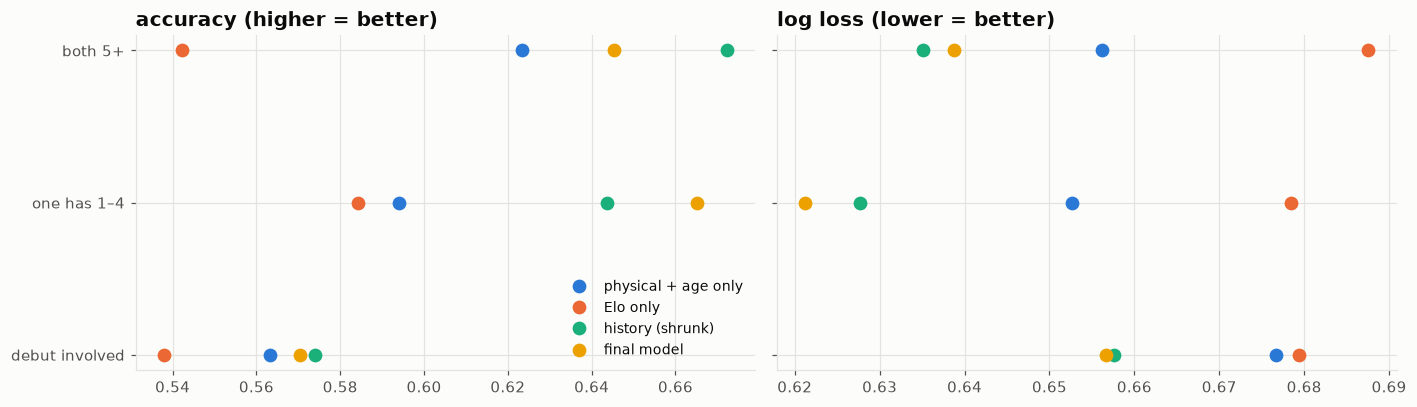

bucket,both 5+,debut involved,one has 1–4
model,,,
Elo only,0.542,0.538,0.584
final model,0.645,0.570,0.665
history (shrunk),0.672,0.574,0.644
physical + age only,0.623,0.563,0.594


In [2]:
share = pd.DataFrame({"train": train.experience.value_counts(normalize=True), "test": test.experience.value_counts(normalize=True)})
display((share * 100).round(1).T.style.format("{:.1f}%"))

models = {"physical + age only": PHYS_COLS, "Elo only": ["elo_pre_diff", "red_corner"],
          "history (shrunk)": BASE, "final model": FINAL_COLS}
P = {name: M.predict(M.fit(M.logistic(), train, cols), test, cols) for name, cols in models.items()}
rows = []
for name, p in P.items():
    for b, g in test.groupby("experience", observed=True):
        i = g.index
        rows.append({"model": name, "bucket": b, "fights": len(g), "accuracy": accuracy_score(g.red_win, p[i] > 0.5),
                     "log loss": log_loss(g.red_win, p[i], labels=[0, 1])})
by_bucket = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
buckets = list(test.experience.cat.categories)
for ax, metric in zip(axes, ["accuracy", "log loss"]):
    for i, name in enumerate(models):
        d = by_bucket[by_bucket.model == name].set_index("bucket").reindex(buckets)
        ax.plot(d[metric], range(len(buckets)), marker="o", ms=8, lw=0, color=SERIES[i], label=name)
    ax.set_yticks(range(len(buckets)), buckets); ax.set_title(metric + (" (higher = better)" if metric == "accuracy" else " (lower = better)"))
axes[0].legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()
by_bucket.pivot(index="model", columns="bucket", values="accuracy").round(3)

**Reading this:**
- About **1 in 5** test fights involves a UFC debutant, and those are the hardest: every model sits around **54–57%**. With no UFC history, there's little to go on.
- In debut fights the **physical + age model is almost as good as the full model** (56% vs 57%). When history is missing, age and size really are most of what's left, but they're weak signals.
- Once both fighters have a few fights, history takes over: about 64–67% for the history-based models, against about 59–62% for physical traits alone.

**Do the weights change when records are short?** Fit the final model separately inside each bucket (training years only), then compare the coefficients of a few key features.
If physical traits matter *more* when there's little history, their bars should be bigger in the "debut involved" bucket.

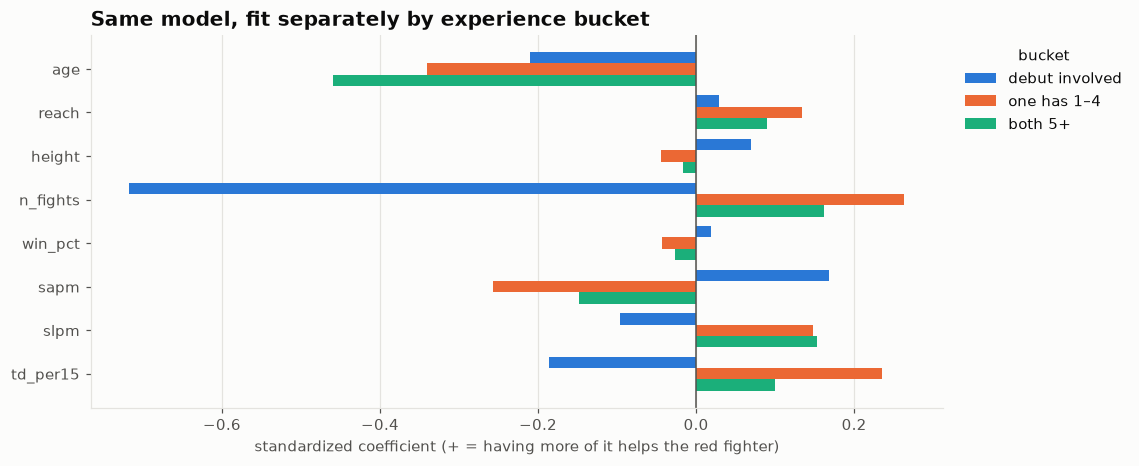

interaction model vs shared model: Δ log loss -0.0008  95% [-0.0032, +0.0016]


,coefficient
age_at_fight_diff,-0.475
reach_diff,0.069
height_diff,-0.000
age_at_fight_x_debut_diff,0.123
reach_x_debut_diff,-0.005
height_x_debut_diff,0.019
age_at_fight_x_thin_diff,0.101
reach_x_thin_diff,0.039
height_x_thin_diff,-0.024


In [3]:
KEYS = ["age_at_fight_diff", "reach_diff", "height_diff", "n_fights_diff", "win_pct_diff", "sapm_diff", "slpm_diff", "td_per15_diff"]
import warnings
coefs = {}
for b, g in train.groupby("experience", observed=True):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)      # debut bucket: win_pct etc. are all empty, by definition
        m = M.fit(M.logistic(), g, FINAL_COLS)
    coefs[b] = pd.Series(m[-1].coef_[0][:len(FINAL_COLS)], index=FINAL_COLS)[KEYS]
coefs = pd.DataFrame(coefs)[buckets]
fig, ax = plt.subplots(figsize=(10, 4.4))
w = 0.26
y = np.arange(len(KEYS))
for i, b in enumerate(buckets):
    ax.barh(y + (i - 1) * w, coefs[b], height=w, color=SERIES[i], label=b)
ax.set_yticks(y, [k.replace("_diff", "").replace("age_at_fight", "age") for k in KEYS]); ax.invert_yaxis()
ax.axvline(0, color=INK_2, lw=1); ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), title="bucket")
ax.set_xlabel("standardized coefficient (+ = having more of it helps the red fighter)")
ax.set_title("Same model, fit separately by experience bucket")
plt.show()

# one model with experience x physical interactions vs the shared model (chosen fairly: scored on test once)
# names end in _diff so the corner swap flips their sign like every other difference
TAGS = {"debut involved": "debut", "one has 1–4": "thin"}
PHYS = ["age_at_fight", "reach", "height"]
def with_inter(df):
    new = {f"{c}_x_{tag}_diff": df[c + "_diff"] * (df.experience == b).astype(float) for b, tag in TAGS.items() for c in PHYS}
    return pd.concat([df, pd.DataFrame(new, index=df.index)], axis=1)
inter_cols = FINAL_COLS + [f"{c}_x_{tag}_diff" for tag in TAGS.values() for c in PHYS]
p_int = M.predict(M.fit(M.logistic(), with_inter(train), inter_cols), with_inter(test), inter_cols)
d, lo, hi = M.bootstrap_delta(test.red_win, p_int, test.p_red)
print(f"interaction model vs shared model: Δ log loss {d:+.4f}  95% [{lo:+.4f}, {hi:+.4f}]")
im = M.fit(M.logistic(), with_inter(train), inter_cols)
display(pd.Series(im[-1].coef_[0][:len(inter_cols)], index=inter_cols)[[c + "_diff" for c in PHYS] + inter_cols[len(FINAL_COLS):]]
        .round(3).rename("coefficient").to_frame())

**Reading this:**
- **Age matters in every bucket, but *less* when a newcomer is involved.** The interaction terms are positive, meaning they shrink the age effect. A young debutant isn't automatically better, and many are older fighters arriving with long regional careers.
- **The surprise: in debut fights, *more* UFC experience predicts *losing*** (n_fights is strongly negative). That's matchmaking. The UFC books prospects it believes in against veterans, often veterans on the way down. The model is learning the matchmaker's opinion.
- Letting the physical effects vary by bucket doesn't improve test predictions (the interval includes 0). One shared model is fine.
- Debutants' style stats are just the division average after shrinkage, so in the debut bucket those coefficients really describe the *veteran's* style.

## 2 · How the model decides

### 2a · Which features matter overall?
Two ways of measuring it:
- **Coefficients:** how strongly the model leans on each feature, per standard deviation of that feature.
- **Permutation importance:** shuffle one feature across the test fights and measure how much worse the predictions get. Unlike coefficients, this measures how much the model *actually depends* on the feature on fights it hasn't seen.

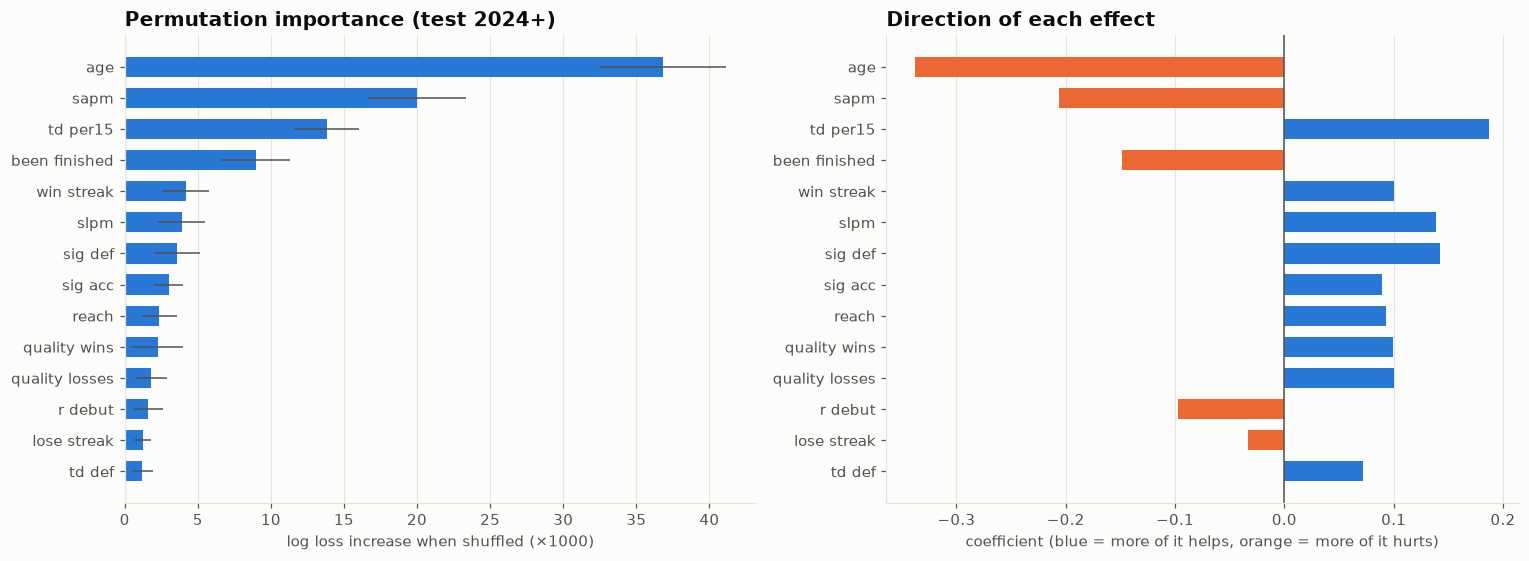

In [4]:
Xte = test.assign(red_corner=1)[FINAL_COLS]
perm = permutation_importance(final, Xte, test.red_win, scoring="neg_log_loss", n_repeats=30, random_state=0)
imp = pd.DataFrame({"importance": perm.importances_mean, "sd": perm.importances_std}, index=FINAL_COLS).sort_values("importance")
coef = pd.Series(final[-1].coef_[0][:len(FINAL_COLS)], index=FINAL_COLS)
top = imp.tail(14)
nice = lambda c: c.replace("_diff", "").replace("age_at_fight", "age").replace("_", " ")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
ax = axes[0]
ax.barh([nice(c) for c in top.index], top.importance * 1000, xerr=top.sd * 1000, color=SERIES[0], height=0.65,
        error_kw={"ecolor": INK_2, "lw": 1})
ax.set_xlabel("log loss increase when shuffled (×1000)"); ax.grid(axis="y", visible=False)
ax.set_title("Permutation importance (test 2024+)")
ax = axes[1]
c = coef[top.index]
ax.barh([nice(i) for i in c.index], c, color=[SERIES[0] if v > 0 else SERIES[1] for v in c], height=0.65)
ax.axvline(0, color=INK_2, lw=1); ax.grid(axis="y", visible=False)
ax.set_xlabel("coefficient (blue = more of it helps, orange = more of it hurts)")
ax.set_title("Direction of each effect")
plt.tight_layout(); plt.show()

**Reading this:** **age** is the single most important feature, with the younger fighter favored. Next come **strikes absorbed per minute** (getting hit a lot is bad), **takedowns per 15 min** (wrestling wins), and **times finished** (a fighter who's been stopped before is easier to stop).
The "who they beat" features (quality wins and losses) matter, but less than the basics.

### 2b · Feature families
Single-feature importance hides features that overlap: shuffle `win_pct` and the model still has `n_fights` and the win counts.
Shuffling a whole **family** at once (the same row shuffle for every column in it) measures what the family *as a whole* contributes.
This uses the model with **all** blocks, so every family from notebook 07 gets a turn.

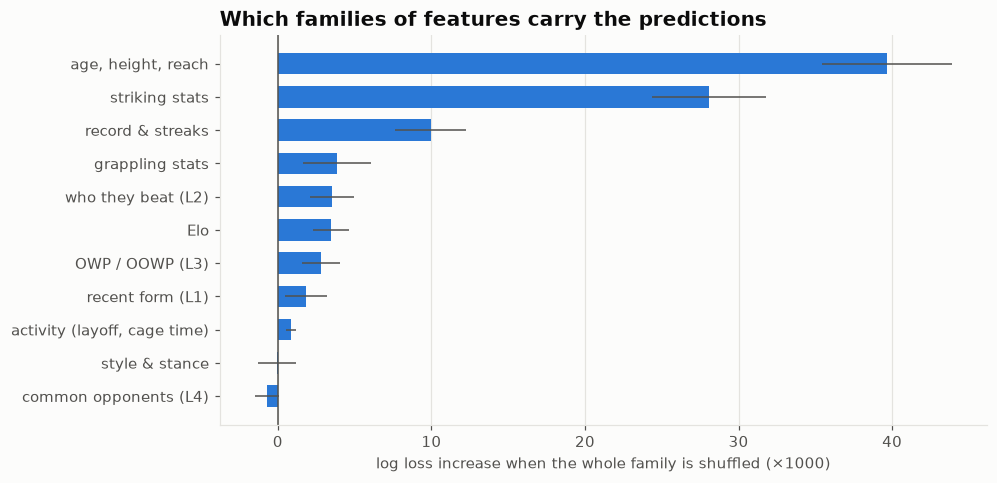

In [5]:
FAMILIES = {
    "record & streaks": ["n_fights", "win_pct", "ko_wins", "sub_wins", "dec_wins", "been_finished", "win_streak", "lose_streak"],
    "striking stats": ["slpm", "sapm", "sig_acc", "sig_def", "kd_per15"],
    "grappling stats": ["td_per15", "td_acc", "td_def", "sub_per15", "ctrl_share"],
    "age, height, reach": ["age_at_fight", "height", "reach", "reach_height"],
    "activity (layoff, cage time)": ["days_since_last", "ufc_minutes"],
    "recent form (L1)": F.FORM_FEATURES,
    "who they beat (L2)": F.OPP_FEATURES,
    "OWP / OOWP (L3)": F.SOS_FEATURES,
    "common opponents (L4)": F.COMMON_FEATURES,
    "style & stance": ["dist_share", "clinch_share", "ground_share", "southpaw"],
    "Elo": ["elo_pre"],
}
full = M.fit(M.logistic(), train, ALL_COLS)
Xall = test.assign(red_corner=1)[ALL_COLS]
base_ll = log_loss(test.red_win, full.predict_proba(Xall)[:, 1])
rng = np.random.default_rng(0)
fam = {}
for name, feats in FAMILIES.items():
    cols = [f + "_diff" for f in feats]
    incs = []
    for _ in range(30):
        Xs = Xall.copy()
        Xs[cols] = Xall[cols].values[rng.permutation(len(Xs))]
        incs.append(log_loss(test.red_win, full.predict_proba(Xs)[:, 1]) - base_ll)
    fam[name] = (np.mean(incs), np.std(incs))
fam = pd.DataFrame(fam, index=["importance", "sd"]).T.sort_values("importance")
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(fam.index, fam.importance * 1000, xerr=fam.sd * 1000, color=SERIES[0], height=0.65, error_kw={"ecolor": INK_2, "lw": 1})
ax.axvline(0, color=INK_2, lw=1); ax.grid(axis="y", visible=False)
ax.set_xlabel("log loss increase when the whole family is shuffled (×1000)")
ax.set_title("Which families of features carry the predictions")
plt.show()

**Reading this:** shuffled as families, **age/height/reach** and **striking stats** carry most of the model, followed by record and grappling.
Your layers (who they beat, OWP, recent form) and Elo each add a small, real amount. Style shares and common opponents add nothing, which matches the ablation in notebook 07.

### 2c · The shape of the big effects
A logistic regression can only draw straight lines. **Gradient boosting** can bend: maybe reach matters up to a point and then stops.
**Partial dependence** shows the boosted model's average predicted win chance as one feature changes, with everything else left as it is.

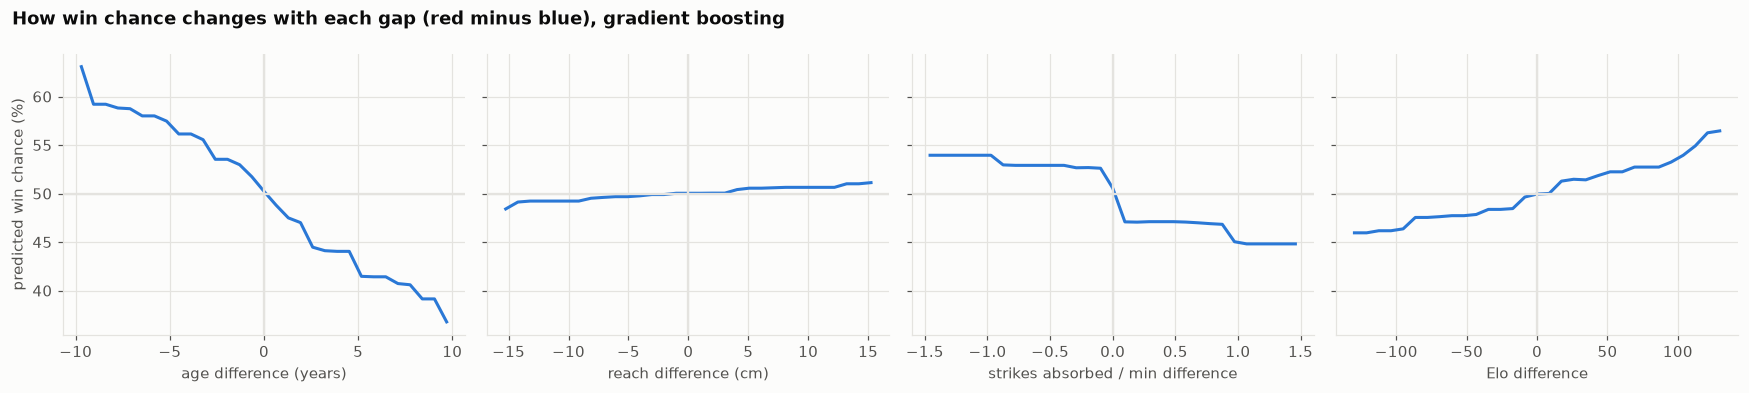

In [6]:
hgb = M.fit(M.boosted(), train, ALL_COLS)
aug = M.augment(train)
SHAPE = ["age_at_fight_diff", "reach_diff", "sapm_diff", "elo_pre_diff"]
labels = {"age_at_fight_diff": "age difference (years)", "reach_diff": "reach difference (cm)",
          "sapm_diff": "strikes absorbed / min difference", "elo_pre_diff": "Elo difference"}
# partial dependence by hand: set the feature to each grid value for every fight, average the win chance
sample = aug[ALL_COLS].sample(3000, random_state=0)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, f in zip(axes, SHAPE):
    lo_, hi_ = aug[f].quantile([0.03, 0.97])
    grid_v = np.linspace(lo_, hi_, 31)
    avg = [hgb.predict_proba(sample.assign(**{f: v}))[:, 1].mean() for v in grid_v]
    ax.plot(grid_v, np.array(avg) * 100, color=SERIES[0])
    ax.axhline(50, color=GRID, lw=1.5); ax.axvline(0, color=GRID, lw=1.5)
    ax.set_xlabel(labels[f])
axes[0].set_ylabel("predicted win chance (%)")
fig.suptitle("How win chance changes with each gap (red minus blue), gradient boosting", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Reading this:**
- **Age is close to a straight line.** Each year younger is worth about 1–1.5 percentage points, so a 10-year age gap is a big edge.
- **Reach barely matters** once everything else is known: ±15 cm moves the needle by about 1 point. It's the most overrated stat in fight commentary.
- **Strikes absorbed acts like a switch:** going from getting hit *less* than the opponent to getting hit *more* swings the win chance by about 6–7 points, and *how much* more barely matters after that.
- **Elo** moves the win chance gently and steadily.

### 2d · One fight at a time
For a logistic model, every prediction is an exact sum: **starting point + each feature's push**, converted to a probability.
The chart shows the biggest pushes for one fight: blue bars push toward the red-corner fighter, orange toward the blue-corner fighter.

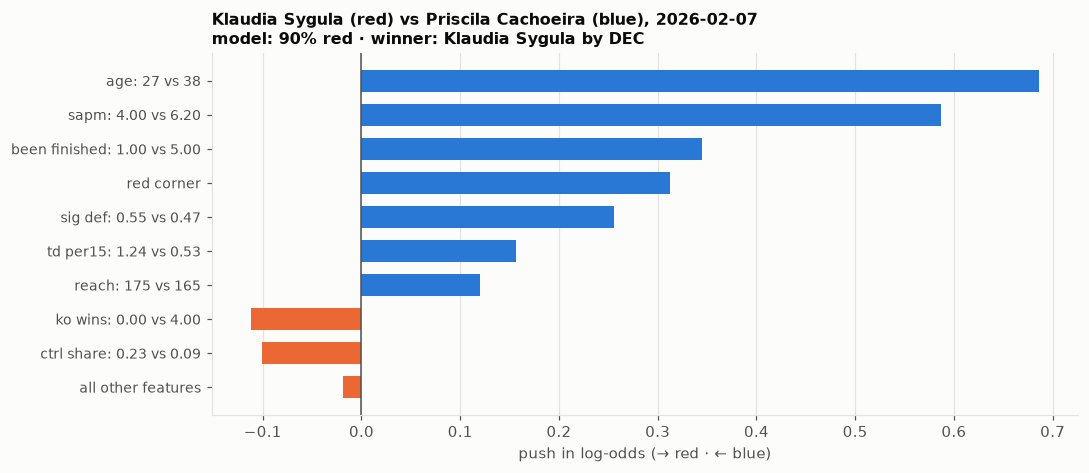

In [7]:
SHOW = ["n_fights", "win_pct", "age_at_fight", "height", "reach", "slpm", "sapm", "sig_acc", "sig_def", "td_per15", "td_def",
        "sub_per15", "kd_per15", "ctrl_share", "win_streak", "lose_streak", "days_since_last", "ufc_minutes",
        "ko_wins", "sub_wins", "dec_wins", "been_finished", "td_acc"] + F.OPP_FEATURES

def explain(row, ax, n=9):
    X = pd.DataFrame([row]).assign(red_corner=1)[FINAL_COLS]
    contrib, b0 = M.contributions(final, X)
    s = contrib.iloc[0]
    s = s[s.abs() > 1e-9].sort_values(key=abs, ascending=False)
    top, rest = s.head(n), s.iloc[n:].sum()
    def lab(c):
        if c.startswith("missing: "):
            return c.replace("_diff", "").replace("_", " ")
        f = c.replace("_diff", "")
        if f in ("r_debut", "b_debut", "reach_missing", "red_corner"):
            return f.replace("_", " ")
        rv, bv = row.get("r_" + f), row.get("b_" + f)
        fmt = lambda v: "–" if pd.isna(v) else (f"{v:.2f}" if abs(v) < 10 else f"{v:.0f}")
        return f"{nice(c)}: {fmt(rv)} vs {fmt(bv)}"
    vals = list(top.values) + [rest]
    names = [lab(c) for c in top.index] + ["all other features"]
    yy = np.arange(len(vals))[::-1]
    ax.barh(yy, vals, color=[SERIES[0] if v > 0 else SERIES[1] for v in vals], height=0.65)
    ax.set_yticks(yy, names, fontsize=9); ax.axvline(0, color=INK_2, lw=1); ax.grid(axis="y", visible=False)
    p = 1 / (1 + np.exp(-(contrib.iloc[0].sum() + b0)))
    actual = row.r_fighter if row.red_win == 1 else row.b_fighter
    ax.set_title(f"{row.r_fighter} (red) vs {row.b_fighter} (blue), {row.date:%Y-%m-%d}\n"
                 f"model: {p:.0%} red · winner: {actual} by {row.method_group}", fontsize=10.5, loc="left")
    ax.set_xlabel("push in log-odds (→ red · ← blue)")

# example: the most confident correct pick in the test set
ex = test.loc[(test.p_winner).idxmax()]
fig, ax = plt.subplots(figsize=(10, 4.4)); explain(ex, ax); plt.tight_layout(); plt.show()

The **red corner** bar is real. Red-corner fighters (usually the higher-ranked, promoted fighter) win more than their stats say, and the model learned that as a constant push.
Rate stats are shown *after* shrinkage, so a fighter with few fights shows values close to the division average.

## 3 · Where the model is wrong

### 3a · Calibration first
A good model isn't one that is never wrong. It's one where "70% favorites" win about 70% of the time. If that holds, the misses are honest upsets, not a broken model.

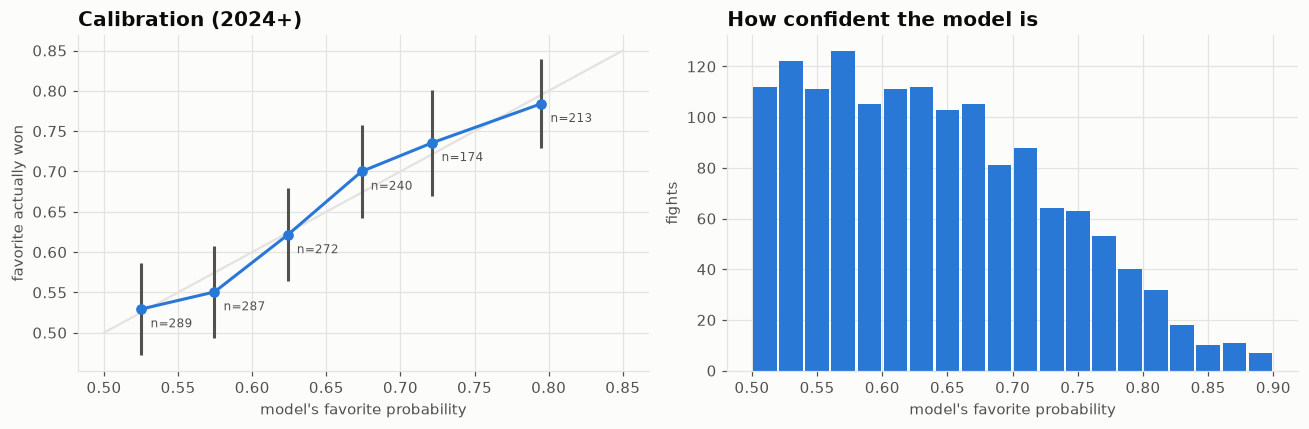

p_red,"(0.5, 0.55]","(0.55, 0.6]","(0.6, 0.65]","(0.65, 0.7]","(0.7, 0.75]","(0.75, 1.0]"
pred,0.525,0.574,0.624,0.674,0.722,0.795
won,0.529,0.551,0.621,0.700,0.736,0.784
n,289.000,287.000,272.000,240.000,174.000,213.000


In [8]:
fav = np.maximum(test.p_red, 1 - test.p_red)
fav_won = test.correct.astype(float)
bins = pd.cut(fav, [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 1.0])
cal = pd.DataFrame({"pred": fav, "won": fav_won}).groupby(bins, observed=True).agg(pred=("pred", "mean"), won=("won", "mean"), n=("won", "size"))
se = np.sqrt(cal.won * (1 - cal.won) / cal.n)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot([0.5, 0.85], [0.5, 0.85], color=GRID, lw=1.5)
ax.errorbar(cal.pred, cal.won, yerr=1.96 * se, fmt="o-", color=SERIES[0], ecolor=INK_2, capsize=0)
for x, yv, n in zip(cal.pred, cal.won, cal.n):
    ax.annotate(f"n={n}", (x, yv), xytext=(6, -12), textcoords="offset points", fontsize=8, color=INK_2)
ax.set_xlabel("model's favorite probability"); ax.set_ylabel("favorite actually won"); ax.set_title("Calibration (2024+)")
ax = axes[1]
ax.hist(fav, bins=np.arange(0.5, 0.92, 0.02), color=SERIES[0], rwidth=0.9)
ax.set_xlabel("model's favorite probability"); ax.set_ylabel("fights"); ax.set_title("How confident the model is")
plt.tight_layout(); plt.show()
cal.round(3).T

**Reading this:** the model is **well calibrated**. Its 70–75% favorites won 74%, and its 75%+ favorites won 78%. So most misses aren't model failures; they're the upsets the probabilities already allowed for.
The model rarely goes above 80%. With these features, a fight is almost never a lock.

### 3b · Which kinds of fights does it miss?
Accuracy by segment, with 95% intervals. The dashed line is overall accuracy.

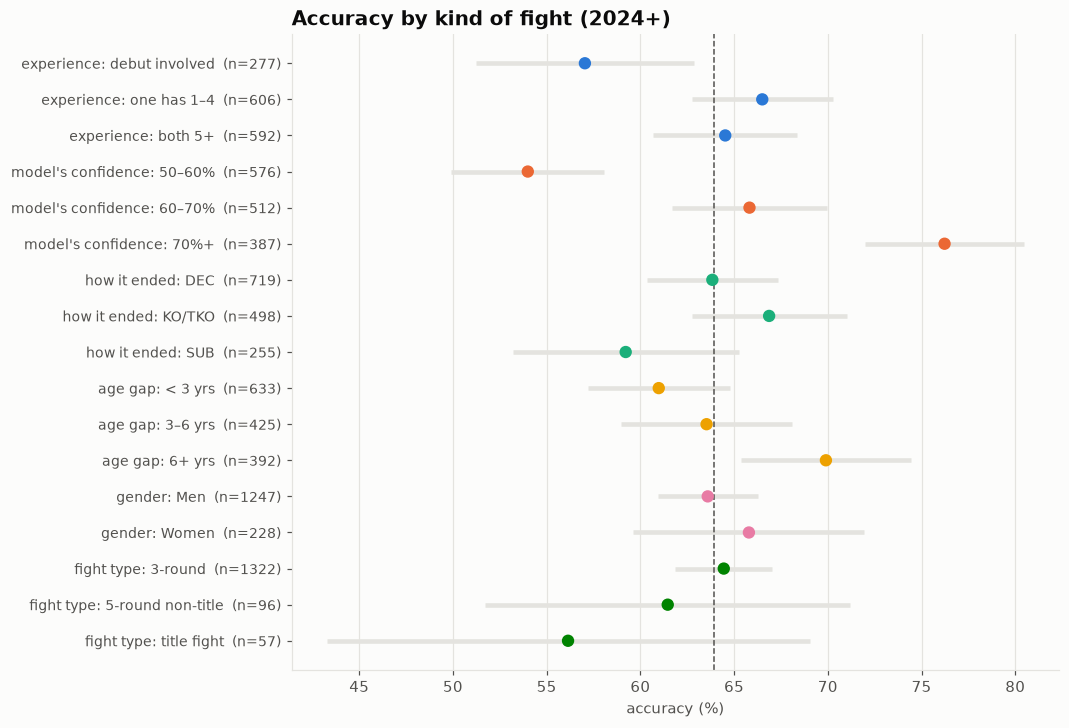

In [9]:
seg = test.copy()
younger_won = np.sign(seg.age_at_fight_diff) != np.sign(seg.red_win * 2 - 1)
seg["age gap"] = pd.cut(seg.age_at_fight_diff.abs(), [-0.1, 3, 6, 99], labels=["< 3 yrs", "3–6 yrs", "6+ yrs"])
seg["model's confidence"] = pd.cut(fav, [0.5, 0.6, 0.7, 1], labels=["50–60%", "60–70%", "70%+"])
seg["how it ended"] = seg.method_group.where(seg.method_group.isin(["KO/TKO", "SUB", "DEC"]), "Other")
seg["fight type"] = np.select([seg.is_title_bout == 1, seg.five_rounds == 1], ["title fight", "5-round non-title"], "3-round")
GROUPS = ["experience", "model's confidence", "how it ended", "age gap", "gender", "fight type"]
rows = []
for g in GROUPS:
    for lvl, d in seg.groupby(g, observed=True):
        acc = d.correct.mean(); se_ = np.sqrt(acc * (1 - acc) / len(d))
        rows.append({"group": g, "level": str(lvl), "accuracy": acc, "lo": acc - 1.96 * se_, "hi": acc + 1.96 * se_, "n": len(d)})
segs = pd.DataFrame(rows)
segs = segs[segs.n >= 20]            # e.g. 3 DQ / "Other" finishes: too few to say anything
fig, ax = plt.subplots(figsize=(9, 7.5))
yy = np.arange(len(segs))[::-1]
ax.hlines(yy, segs.lo * 100, segs.hi * 100, color=GRID, lw=3)
ax.scatter(segs.accuracy * 100, yy, color=[SERIES[GROUPS.index(g) % 8] for g in segs.group], s=50, zorder=3)
ax.axvline(test.correct.mean() * 100, color=INK_2, ls="--", lw=1)
ax.set_yticks(yy, [f"{g}: {l}  (n={n})" for g, l, n in zip(segs.group, segs.level, segs.n)], fontsize=9)
ax.grid(axis="y", visible=False); ax.set_xlabel("accuracy (%)"); ax.set_title("Accuracy by kind of fight (2024+)")
plt.show()

**Reading this:**
- **Confidence is the biggest divider:** about 54% accuracy on 50–60% calls vs about 76% on 70%+ calls. That's exactly what calibration should look like.
- **Debut fights** are the weakest group (about 57%).
- **Submissions are harder to see coming than knockouts** (about 59% vs 67%).
- **Big age gaps are the easiest** (about 70% with 6+ years).
- Title fights look low, but with only 57 of them the interval is huge; it could be noise.

### 3c · Misses vs hits
How do the fights the model gets wrong differ from the ones it gets right?

In [10]:
cmp = pd.DataFrame({
    "model's favorite probability": fav,
    "|Elo gap|": test.elo_pre_diff.abs(),
    "|age gap| (yrs)": test.age_at_fight_diff.abs(),
    "fewer UFC fights of the two": np.minimum(test.r_n_fights, test.b_n_fights),
    "ended by KO/TKO": (test.method_group == "KO/TKO").astype(float),
    "ended by SUB": (test.method_group == "SUB").astype(float),
    "went to decision": (test.method_group == "DEC").astype(float),
    "underdog was the younger fighter": np.where(test.p_red > 0.5, test.age_at_fight_diff > 0, test.age_at_fight_diff < 0).astype(float),
    "outcome": np.where(test.correct, "model right", "model wrong"),
}).groupby("outcome").mean().T
cmp["wrong − right"] = cmp["model wrong"] - cmp["model right"]
cmp.round(3)

outcome,model right,model wrong,wrong − right
model's favorite probability,0.652,0.616,-0.036
|Elo gap|,55.295,50.408,-4.887
|age gap| (yrs),4.560,3.958,-0.602
fewer UFC fights of the two,4.480,4.461,-0.020
ended by KO/TKO,0.353,0.310,-0.043
ended by SUB,0.160,0.195,0.035
went to decision,0.487,0.489,0.002
underdog was the younger fighter,0.280,0.383,0.104


**Reading this:** misses are mostly **close fights**: smaller Elo and age gaps, and lower confidence.
The clearest pattern: in **38%** of misses the underdog was the *younger* fighter, against 28% of hits. When the model favors the older fighter (on record or stats), youth is what beats it.
Misses also end by submission a bit more often. A submission can come from one scramble that no career average predicts.

### 3d · The biggest upsets
Fights where the model gave the eventual winner the lowest chance.

,date,winner,beat,model gave winner,how,round,winner's UFC fights,loser's UFC fights,weight class
0,2026-06-14,Justin Gaethje,Ilia Topuria,11%,KO/TKO,4,15,9,Lightweight
1,2026-09-19,Sean Sharaf,Gable Steveson,14%,KO/TKO,1,2,1,Heavyweight
2,2026-05-09,Sean Strickland,Khamzat Chimaev,15%,DEC,5,24,9,Middleweight
3,2026-09-05,Modestas Bukauskas,Oumar Sy,16%,KO/TKO,2,13,5,Light Heavyweight
4,2025-03-15,Priscila Cachoeira,Josiane Nunes,16%,KO/TKO,1,10,5,Women's Bantamweight
5,2025-08-16,Alexander Hernandez,Chase Hooper,16%,KO/TKO,1,15,11,Lightweight
6,2026-05-02,Carlos Prates,Jack Della Maddalena,16%,KO/TKO,3,7,9,Welterweight
7,2024-08-17,Dan Hooker,Mateusz Gamrot,17%,DEC,3,21,9,Lightweight
8,2025-01-18,Raoni Barcelos,Payton Talbott,17%,DEC,3,11,3,Bantamweight
9,2026-10-17,Jasmine Jasudavicius,Erin Blanchfield,18%,DEC,3,12,9,Women's Flyweight


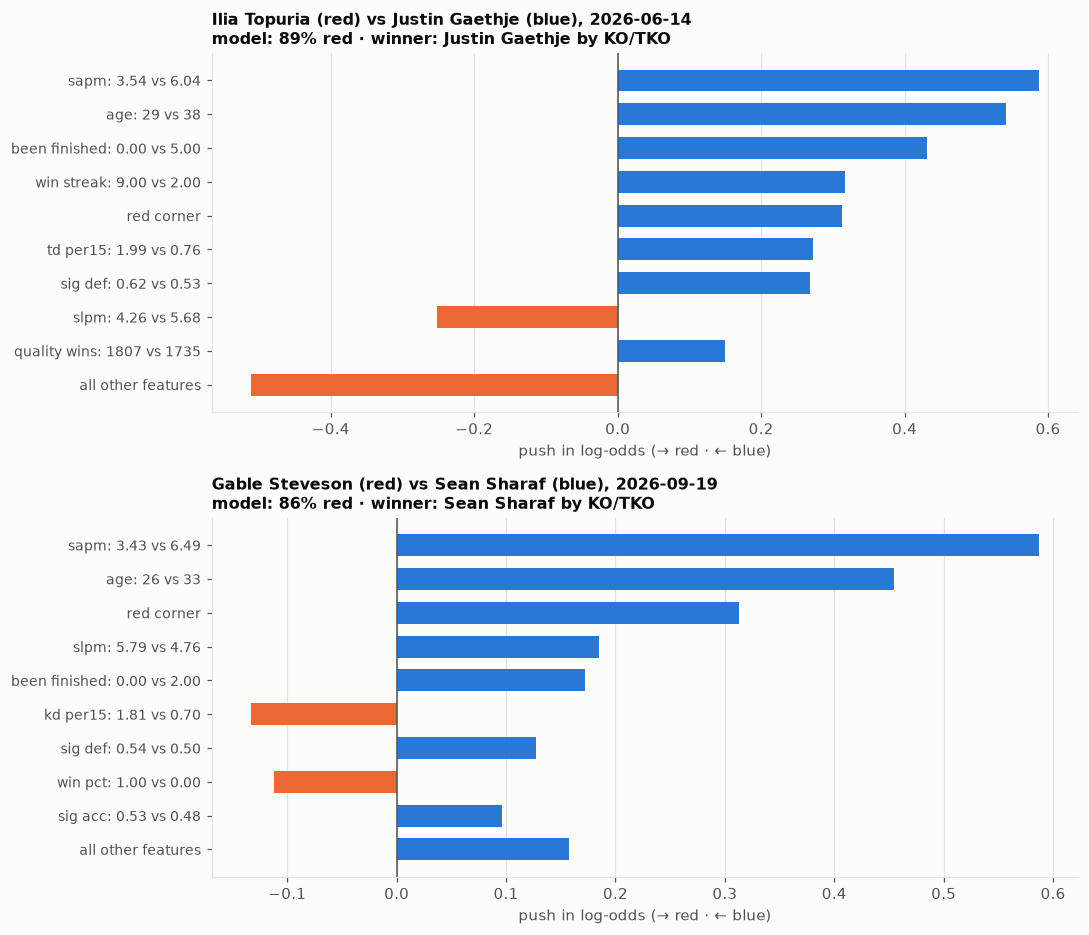

In [11]:
ups = test.sort_values("p_winner").head(10)
display(pd.DataFrame({"date": ups.date.dt.date, "winner": ups.winner_name, "beat": ups.loser_name,
                      "model gave winner": (ups.p_winner * 100).round(0).astype(int).astype(str) + "%",
                      "how": ups.method_group, "round": ups.finish_round,
                      "winner's UFC fights": np.where(ups.red_win == 1, ups.r_n_fights, ups.b_n_fights),
                      "loser's UFC fights": np.where(ups.red_win == 1, ups.b_n_fights, ups.r_n_fights),
                      "weight class": ups.weight_class}).reset_index(drop=True))
fig, axes = plt.subplots(2, 1, figsize=(10, 8.6))
for ax, (_, r) in zip(axes, ups.head(2).iterrows()):
    explain(r, ax)
plt.tight_layout(); plt.show()

**Reading the upsets:** the biggest misses are mostly **knockouts**, where one punch overrides every stat.
- In the top upset, the model loved the favorite's defense, youth and clean record. The underdog won by KO anyway.
- In the second, the "favorite" had **one** UFC fight. A strong-looking record built on a single fight is exactly where small samples bite, even after shrinkage.

## 4 · Worked examples: the matchup card
This is the prototype of the website's matchup page: both lead-ups, the "who did they beat" numbers, and the model's call on **who** and **how**.
The examples are the three 2024+ title fights with the highest combined Elo, picked by rule, not by hand.

In [12]:
prior = train[train.method_group.isin(M.METHODS)].method_group.value_counts(normalize=True).to_dict()
test_m = M.method_probs(test, test.p_red, prior, k=K_METHOD, loser_weight=0)
win_streak = ff.set_index(F.KEY).win_streak

def lead_up(name, before, n=5):
    p = ff[(ff.fighter == name) & (ff.date < before)].sort_values("date").tail(n)
    return pd.DataFrame({"date": p.date.dt.date.values, "opponent": p.opponent.values, "result": p.result.values,
                         "method": p.method_group.values,
                         "opp. streak going in": [win_streak.get((f, o)) for f, o in zip(p.fight_id, p.opponent)]})

CARD = {"age": "age_at_fight", "reach (cm)": "reach", "UFC record W-L": None, "last-5 wins": "l5_win_rate",
        "longest streak snapped (last 5)": "beat_streak_max", "avg Elo of opponents beaten": "quality_wins",
        "opponents' win rate (OWP)": "owp", "Elo": "elo_pre"}

def card(row):
    def side(pre):
        out = {}
        for k, c in CARD.items():
            if c is None:
                out[k] = f"{int(row[pre + 'n_fights'] * row[pre + 'win_pct']) if row[pre + 'n_fights'] else 0}-" \
                         f"{int(row[pre + 'n_fights'] - round(row[pre + 'n_fights'] * row[pre + 'win_pct'])) if row[pre + 'n_fights'] else 0}"
            elif c == "l5_win_rate":
                out[k] = f"{row[pre + 'l5_win_rate'] * row[pre + 'l5_fights']:.0f} of {row[pre + 'l5_fights']:.0f}"
            else:
                v = row[pre + c]
                out[k] = "–" if pd.isna(v) else (f"{v:.2f}" if abs(v) < 2 else f"{v:.0f}")
        return out
    tab = pd.DataFrame({row.r_fighter: side("r_"), row.b_fighter: side("b_")})
    probs = test_m.loc[row.name].sort_values(ascending=False).head(4)
    name = lambda o: o.replace("Red", row.r_fighter).replace("Blue", row.b_fighter)
    print(f"\n{'=' * 90}\n{row.r_fighter} vs {row.b_fighter} · {row.date:%Y-%m-%d} · {row.weight_class} title")
    display(tab)
    for n_, pre in [(row.r_fighter, "r_"), (row.b_fighter, "b_")]:
        print(f"{n_}: last 5"); display(lead_up(n_, row.date))
    print(f"model: {row.r_fighter} {row.p_red:.0%} · {row.b_fighter} {1 - row.p_red:.0%}")
    print("most likely outcomes: " + " · ".join(f"{name(o)} {v:.0%}" for o, v in probs.items()))
    print(f"ACTUAL: {row.winner_name} by {row.method_group} (round {row.finish_round})")

titles = test[test.is_title_bout == 1].assign(elo_sum=lambda d: d.r_elo_pre + d.b_elo_pre).nlargest(3, "elo_sum")
for _, r in titles.iterrows():
    card(r)


Jon Jones vs Stipe Miocic · 2024-11-16 · Heavyweight title


,Jon Jones,Stipe Miocic
age,37,42
reach (cm),213,203
UFC record W-L,21-2,14-4
last-5 wins,5 of 5,3 of 5
longest streak snapped (last 5),6,7
avg Elo of opponents beaten,1730,1827
opponents' win rate (OWP),0.59,0.58
Elo,2009,1853


Jon Jones: last 5


,date,opponent,result,method,opp. streak going in
0,2018-12-29,Alexander Gustafsson,W,KO/TKO,2
1,2019-03-02,Anthony Smith,W,DEC,3
2,2019-07-06,Thiago Santos,W,DEC,4
3,2020-02-08,Dominick Reyes,W,DEC,6
4,2023-03-04,Ciryl Gane,W,SUB,1


Stipe Miocic: last 5


...

Islam Makhachev: last 5


,date,opponent,result,method,opp. streak going in
0,2023-02-11,Alexander Volkanovski,W,DEC,12
1,2023-10-21,Alexander Volkanovski,W,KO/TKO,1
2,2024-06-01,Dustin Poirier,W,SUB,1
3,2025-01-18,Renato Moicano,W,SUB,4
4,2025-11-15,Jack Della Maddalena,W,DEC,8


Ian Machado Garry: last 5


,date,opponent,result,method,opp. streak going in
0,2024-02-17,Geoff Neal,W,DEC,0
1,2024-06-29,Michael Page,W,DEC,1
2,2024-12-07,Shavkat Rakhmonov,L,DEC,6
3,2025-04-26,Carlos Prates,W,DEC,4
4,2025-11-22,Belal Muhammad,W,DEC,0


model: Islam Makhachev 78% · Ian Machado Garry 22%
most likely outcomes: Islam Makhachev SUB 31% · Islam Makhachev DEC 30% · Islam Makhachev KO/TKO 17% · Ian Machado Garry DEC 14%
ACTUAL: Islam Makhachev by DEC (round 5)


## Takeaways
1. **Short records:**
   - About 1 in 5 fights involves a UFC debutant, and those are close to coin flips (about 57%).
   - When history is missing, age and size carry most of what's left, but they're weak. The biggest signal in debut fights is actually *matchmaking*: prospects are booked to beat veterans.
   - **Shrinkage** is the right fix for short records: it lets a 2-fight fighter count without trusting 2 fights too much.
2. **What drives the model:** age first, then strikes absorbed, takedowns, and times finished. As families: physical/age and striking dominate, record and grappling come next, and "who they beat", OWP and Elo add a little each. Reach and style shares barely matter.
3. **The model is honest about uncertainty.** It's well calibrated, and its misses are concentrated in low-confidence fights, debut fights, submissions, and fights where the underdog is younger.
4. **The worked examples show the full who-and-how output.** For Jones vs Miocic it was right on who but wrong on how (it expected a decision; it was a KO). That's normal: method is the harder half.
5. **For the simulator:** use the shrunk history + "who they beat" win model, and the two-step method model. The calibration plots show the probabilities can be trusted for sampling outcomes.